![Banner](../../../../Images/Banner/05_geostat/07_simulation.png)

# Plurigaussian Simulation (`PluriGaussianSimulator`)

**Dataset:** Jura soil survey, Swiss Jura (`Data/00_shared/data_geostatistics/jura_data.csv`, 359 samples with the rock type at each site) + prediction grid (`Data/00_shared/data_geostatistics/jura_grid.csv`, 5,957 nodes on a 50 m lattice with the mapped geology)

**Target:** Rock type (`Rock`): five geological units, four Jurassic formations and Quaternary deposits

**Library:** `geolattice.geostatistics`: `PluriGaussianSimulator`, `TruncationRule`, `pgsim`, `category_probabilities`, `category_proportions` (module `geolattice.geostatistics.simulation.pgs`)

**Before this notebook:** [Introduction to geostatistical simulation](05_07_00_introduction_geostatistical_sumulations.ipynb) and [sequential indicator co-simulation](05_07_04_sicosim.ipynb) (the categorical alternative compared here).

***

## Table of Contents

1. [Overview](#overview)
2. [Theory](#theory)
    - 2.1 [Facies from truncated Gaussian fields](#facies-from-truncated-gaussian-fields)
    - 2.2 [The truncation rule](#the-truncation-rule)
    - 2.3 [Proportions](#proportions)
    - 2.4 [Contacts](#contacts)
    - 2.5 [Indicator variograms from latent variograms](#indicator-variograms-from-latent-variograms)
    - 2.6 [Conditioning: the Gibbs sampler](#conditioning-the-gibbs-sampler)
    - 2.7 [Simulating the latent fields](#simulating-the-latent-fields)
    - 2.8 [The algorithm](#the-algorithm)
3. [Python Setup](#python-setup)
4. [Jura Rock Types and Their Contacts](#jura-rock-types-and-their-contacts)
5. [Designing the Truncation Rule](#designing-the-truncation-rule)
6. [Inferring the Latent Variograms](#inferring-the-latent-variograms)
7. [Unconditional Simulation: Latent Fields and Facies](#unconditional-simulation-latent-fields-and-facies)
8. [Conditional Simulation](#conditional-simulation)
9. [Contacts: PGS vs Truncated Gaussian vs SIS](#contacts-pgs-vs-truncated-gaussian-vs-sis)
10. [Validation against the Geology Map and Held-Out Samples](#validation-against-the-geology-map-and-held-out-samples)
11. [Choosing the Latent Variogram Type](#choosing-the-latent-variogram-type)
12. [Correlated Latent Fields: the Effect of $\rho$](#correlated-latent-fields-the-effect-of-rho)
13. [Visualization of Uncertainty](#visualization-of-uncertainty)
    - 13.1 [Animated display of realizations](#animated-display-of-realizations)
    - 13.2 [Probability and entropy maps](#probability-and-entropy-maps)
14. [Run Time](#run-time)
15. [Summary and Conclusions](#summary-and-conclusions)
    - 15.1 [Choosing the options](#choosing-the-options)
16. [References](#references)

***
## Overview

Geological units do not touch at random. In a stratigraphic sequence a formation lies between the one below and the one above, so on a map it borders those two and, wherever erosion or cover cuts across, younger deposits. Sequential indicator simulation (SIS) knows nothing about this. It kriges each class's probability separately, so any class can appear next to any other. **Plurigaussian simulation** (PGS; Le Loc'h & Galli, 1997; Armstrong et al., 2003) builds that knowledge in.

PGS simulates one or two continuous **latent Gaussian fields** and turns them into categories with a **truncation rule**: a partition of the latent space into regions, one or more per category. Two categories can be in contact in a realization only if their regions share an edge in the rule. The rule therefore controls the **contacts**, and with the latent variograms it also controls the **proportions** and the **shapes** of the units.

| Object | What it does |
|---|---|
| `TruncationRule` | The rule, as rectangles in probability space $[0,1]^2$. Constructors: `truncated_gaussian` (one field, ordered categories), `hierarchical` (one category on $Y_1$, the others stacked along $Y_2$), `from_flag` (any rule drawn as an image). It also has `proportions(rho)` and `classify(y1, y2)`. |
| `PluriGaussianSimulator` | `fit(grid, df, x, y, cat)` and `simulate(nsim, seed, return_latent=False)`. A Gibbs sampler conditions the latent fields to the categorical data, and the latent fields are simulated by FFT on a lattice or by turning bands. |
| `pgsim` | One-call wrapper (with `labels=True` for category names). |
| `category_probabilities`, `category_proportions` | Per-node class frequencies and per-realization proportions. |

The Jura geology is a clean test, because the mapped geology gives a reference for contacts:

* the four Jurassic formations are in stratigraphic order: Argovian, Sequanian, Kimmeridgian, Portlandian;
* Quaternary deposits cover all of them.

The notebook:

* measures the contacts on the geology map and designs a **hierarchical rule** from them;
* infers the latent variograms from the indicator variograms of 259 samples;
* conditions the simulation to the samples, and checks it;
* compares PGS with a single-field truncated Gaussian rule and with SIS on contacts, proportions and agreement with the map.

***
## Theory

### Facies from truncated Gaussian fields

Let $A(\mathbf{u})$ and $B(\mathbf{u})$ be independent stationary standard Gaussian random fields with correlograms $\rho_A(\mathbf{h})$ and $\rho_B(\mathbf{h})$ (variograms with sill 1). The **latent fields** are

$$
Y_1(\mathbf{u}) = A(\mathbf{u}), \qquad Y_2(\mathbf{u}) = \rho\, A(\mathbf{u}) + \sqrt{1 - \rho^2}\, B(\mathbf{u}),
$$

so $\operatorname{corr}(Y_1, Y_2) = \rho$ at the same location. The category at $\mathbf{u}$ is

$$
S(\mathbf{u}) = s_k \iff \bigl(Y_1(\mathbf{u}), Y_2(\mathbf{u})\bigr) \in D_k ,
$$

where $D_1, \dots, D_K$ partition the plane. With one field ($D_k$ are intervals of $Y_1$), this is **truncated Gaussian simulation** (Matheron et al., 1987).

### The truncation rule

`TruncationRule` describes each $D_k$ as one or more rectangles in **probability space**, $u_j = \Phi(y_j) \in [0, 1]$, so a rule is a tiling of the unit square:

$$
D_k = \bigcup_{r \in R_k} [u_{1,r}^-, u_{1,r}^+) \times [u_{2,r}^-, u_{2,r}^+) .
$$

The constructors:

* **`truncated_gaussian(p)`:** one field. Category $k$ is $U_1 \in [P_{k-1}, P_k)$ with $P_k = \sum_{j \le k} p_j$. Categories are **ordered**: each touches only its neighbours in the sequence.
* **`hierarchical(p)`:** the first category is $U_1 < p_1$, across the whole $U_2$ axis; the others are stacked along $U_2$ in the strip $U_1 \ge p_1$. The first category can touch **every** other one; the others touch only their neighbours in the stack.
* **`from_flag(flag)`:** any rule drawn as a small image. `flag[i, j]` is the category of cell $(i, j)$ of a grid on $[0,1]^2$, rows along $U_1$ and columns along $U_2$.

### Proportions

The proportion of category $k$ is the probability that $(Y_1, Y_2)$ falls in $D_k$:

$$
p_k = \sum_{r \in R_k} P\bigl\{y_{1,r}^- \le Y_1 < y_{1,r}^+,\; y_{2,r}^- \le Y_2 < y_{2,r}^+\bigr\},
$$

a bivariate normal rectangle probability with correlation $\rho$ (`rule.proportions(rho)`). For $\rho = 0$ it factorizes into $(u_1^+ - u_1^-)(u_2^+ - u_2^-)$, so a rule built from target proportions with $\rho = 0$ reproduces them exactly. With $\rho \ne 0$ the same rectangles give different proportions.

### Contacts

Because the latent fields are continuous, a path in space that crosses from $D_j$ to $D_k$ must pass through every region in between. So in a realization, **categories $j$ and $k$ can be adjacent only if $D_j$ and $D_k$ share an edge** in the rule. On a discrete grid a narrow intermediate region can be skipped between two neighbouring cells, so "forbidden" contacts become rare rather than impossible. This is the key difference from SIS, where every pair of classes can touch.

### Indicator variograms from latent variograms

The indicator of category $k$ is $I_k(\mathbf{u}) = \mathbf{1}[(Y_1, Y_2)(\mathbf{u}) \in D_k]$. Its variogram follows from the latent correlograms through bivariate probabilities. For one rectangle with $\rho = 0$, the two independent fields factorize:

$$
\gamma_{I_k}(\mathbf{h}) = p_k - P\{I_k(\mathbf{u}) = 1, I_k(\mathbf{u}+\mathbf{h}) = 1\}
= p_k - \pi_A\bigl(y_1^-, y_1^+; \rho_A(\mathbf{h})\bigr)\, \pi_B\bigl(y_2^-, y_2^+; \rho_B(\mathbf{h})\bigr),
$$

where $\pi(a, b; r) = P\{a \le X < b,\, a \le X' < b\}$ for standard normals $X, X'$ with correlation $r$. This links what can be measured, the indicator variograms of the data, to what PGS needs, the latent correlograms. Section 6 inverts it by least squares.

### Conditioning: the Gibbs sampler

At a datum the category is known, but the latent values are not: they are only known to lie in $D_k$. Before simulating, GeoLattice draws latent values at the $n$ data that are consistent with both the categories and the latent covariance, with a **Gibbs sampler** (Armstrong et al., 2003; Emery, 2007).

With $\mathbf{Q} = \mathbf{C}^{-1}$ the precision matrix of $A$ at the data, the full conditional of $A_i$ given all other $A_j$ is Gaussian, with

$$
E[A_i \mid A_{-i}] = -\frac{1}{Q_{ii}} \sum_{j \ne i} Q_{ij}\, A_j, \qquad \operatorname{Var}[A_i \mid A_{-i}] = \frac{1}{Q_{ii}},
$$

the simple-kriging mean and variance of $A_i$ from all the other data. Each sweep redraws every $A_i$, and then every $B_i$, from that Gaussian **truncated** to the values that keep $(Y_1, Y_2)$ in the observed category's region, given the current value of the other field. For a rectangle with $\rho > 0$, for example,

$$
A_i \in [y_1^-, y_1^+) \cap \left[\frac{y_2^- - \sqrt{1-\rho^2}\, B_i}{\rho},\; \frac{y_2^+ - \sqrt{1-\rho^2}\, B_i}{\rho}\right).
$$

After `gibbs_iter` sweeps (default 200) the chain approximates the joint conditional distribution of the latent values at the data. Each realization gets its own Gibbs draw; the chains run vectorized over realizations.

### Simulating the latent fields

Given the latent values at the data, $A$ and $B$ are simulated **conditionally** on the grid: an unconditional Gaussian field, corrected by simple kriging of the residuals at the data. On a regular lattice this uses the FFT (circulant-embedding) simulator, `method="fft"`, the default when the grid is a lattice. Otherwise it uses turning bands (`method="tb"`). On a lattice, data are first moved to their nearest node; a node holding data of different categories keeps the most frequent one, with a warning. The realization is `rule.classify(Y1, Y2)`, and it reproduces the data categories at their nodes.

### The algorithm

1. Choose the rule (categories, proportions, contacts) and the latent variograms (sill 1), and optionally $\rho$.
2. For each realization:
    1. run the Gibbs sampler for latent values $(A_i, B_i)$ at the data, consistent with their categories;
    2. simulate $A$ and $B$ on the grid conditionally on those values;
    3. form $Y_1 = A$ and $Y_2 = \rho A + \sqrt{1-\rho^2}\, B$, and classify with the rule.

***
## Python Setup

`PluriGaussianSimulator` runs on the CPU. The FFT simulator makes the latent fields fast on a lattice, and the Gibbs sampler is vectorized over realizations. SIS (`IndicatorCoSimulator`) is used as the comparison, on the GPU when available.

**Installation.** This notebook needs installation option 4 (core, spatial analysis, spatial statistics and geostatistics): `pip install "geolattice[geostats]"`. See "Installation options" in the GeoLattice README.

In [1]:
%matplotlib inline
import time
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle
from IPython.display import HTML, display
from scipy.optimize import curve_fit
from scipy.spatial import cKDTree
from scipy.spatial.distance import pdist
from scipy.special import ndtri
from scipy.stats import multivariate_normal

import geolattice.geostatistics as pygstat
from geolattice.geostatistics import (
    IndicatorCoSimulator,
    PluriGaussianSimulator,
    TruncationRule,
    category_probabilities,
    category_proportions,
    pgsim,
)
from geolattice.geostatistics.utils.backend import cupy_gpu_usable

print("pygstat version:", pygstat.__version__)
USE_GPU = cupy_gpu_usable()
print("PluriGaussianSimulator : CPU (FFT latent fields, vectorized Gibbs sampler)")
print(f"SIS baseline           : {'GPU (CuPy)' if USE_GPU else 'CPU'}")

RESULTS = []
def record(section, status, note=""):
    RESULTS.append({"Feature": section, "Status": status, "Notes": note})
    marker = {"PASS": "✅", "FAIL": "❌", "BLOCKED": "⚠️"}.get(status, "?")
    print(f"{marker} [{status}] {section}  {note}")

pygstat version: 0.3.44
PluriGaussianSimulator : CPU (FFT latent fields, vectorized Gibbs sampler)
SIS baseline           : GPU (CuPy)


***
## Jura Rock Types and Their Contacts

The 359 Jura samples record the rock type at each site, and `jura_grid.csv` holds the mapped geology on a 50 m lattice. As in the earlier notebooks, 100 samples are held out at random, and the simulations are conditioned on the other 259.

In [2]:
DATA = "../../../../Data/00_shared/data_geostatistics/"
df_all = pd.read_csv(DATA + "jura_data.csv", index_col=0)
grid_df = pd.read_csv(DATA + "jura_grid.csv", index_col=0)
grid = grid_df[["Xloc", "Yloc"]].to_numpy(dtype=float)
CODE_TO_NAME = {1: "Argovian", 2: "Kimmeridgian", 3: "Sequanian", 4: "Portlandian", 5: "Quaternary"}
STRAT = ["Argovian", "Sequanian", "Kimmeridgian", "Portlandian"]           # oldest -> youngest
NAMES = STRAT + ["Quaternary"]
COLORS = {"Argovian": "#4daf4a", "Sequanian": "#ff7f00", "Kimmeridgian": "#377eb8",
          "Portlandian": "#984ea3", "Quaternary": "#e7d84d"}
CMAP = ListedColormap([COLORS[n] for n in NAMES])
geo_map = grid_df["Rock"].to_numpy(dtype=object)

rng_split = np.random.default_rng(359)
test_idx = np.sort(rng_split.choice(len(df_all), size=100, replace=False))
is_test = np.zeros(len(df_all), bool)
is_test[test_idx] = True
df_all["rock"] = df_all["Rock"].map(CODE_TO_NAME)
df = df_all[~is_test].reset_index(drop=True)
test = df_all[is_test].reset_index(drop=True)
xy, xy_test = df[["Xloc", "Yloc"]].to_numpy(float), test[["Xloc", "Yloc"]].to_numpy(float)

CELL = 0.05
ix = np.rint((grid[:, 0] - grid[:, 0].min()) / CELL).astype(int)
iy = np.rint((grid[:, 1] - grid[:, 1].min()) / CELL).astype(int)
EXTENT = [grid[:, 0].min() - CELL / 2, grid[:, 0].max() + CELL / 2,
          grid[:, 1].min() - CELL / 2, grid[:, 1].max() + CELL / 2]


def to_image(values, fill=np.nan):
    img = np.full((iy.max() + 1, ix.max() + 1), fill, dtype=object if isinstance(fill, str) else float)
    img[iy, ix] = values
    return img


def show_rock(ax, labels, title, points=None):
    codes = np.array([NAMES.index(v) for v in labels], float)
    im = ax.imshow(to_image(codes), origin="lower", extent=EXTENT, cmap=CMAP, vmin=-0.5, vmax=4.5,
                   interpolation="nearest")
    if points is not None:
        ax.scatter(points[:, 0], points[:, 1], s=5, c="k")
    ax.set_title(title)
    ax.set_xlabel("X (km)")
    ax.set_ylabel("Y (km)")
    ax.set_aspect("equal")
    cb = plt.colorbar(im, ax=ax, ticks=range(5), fraction=0.046, pad=0.04)
    cb.ax.set_yticklabels(NAMES)


def show_map(ax, values, title, cmap="viridis", vmin=None, vmax=None, label=""):
    im = ax.imshow(to_image(values), origin="lower", extent=EXTENT, cmap=cmap, vmin=vmin, vmax=vmax,
                   interpolation="nearest")
    ax.set_title(title)
    ax.set_xlabel("X (km)")
    ax.set_ylabel("Y (km)")
    ax.set_aspect("equal")
    plt.colorbar(im, ax=ax, label=label, fraction=0.046, pad=0.04)


def contacts(labels):
    # number of 4-neighbour cell edges between each pair of different units
    img = to_image(np.asarray(labels, dtype=object), fill="")
    M = pd.DataFrame(0, index=NAMES, columns=NAMES)
    for a, b in [(img[1:, :], img[:-1, :]), (img[:, 1:], img[:, :-1])]:
        ok = (a != "") & (b != "") & (a != b)
        for x, y in zip(a[ok], b[ok]):
            M.loc[x, y] += 1
            M.loc[y, x] += 1
    return M


def total_contacts(M):
    return int(np.triu(M.values).sum())


print(f"{len(df)} conditioning samples, {len(test)} held-out samples, {len(grid)} map nodes")
print(pd.DataFrame({"samples (259)": df["rock"].value_counts(normalize=True),
                    "geology map": pd.Series(geo_map).value_counts(normalize=True)}).loc[NAMES].round(3))

259 conditioning samples, 100 held-out samples, 5957 map nodes
              samples (259)  geology map
Argovian              0.208        0.199
Sequanian             0.259        0.273
Kimmeridgian          0.363        0.342
Portlandian           0.012        0.053
Quaternary            0.158        0.133


The contact matrix of the geology map counts the cell edges between each pair of different units:

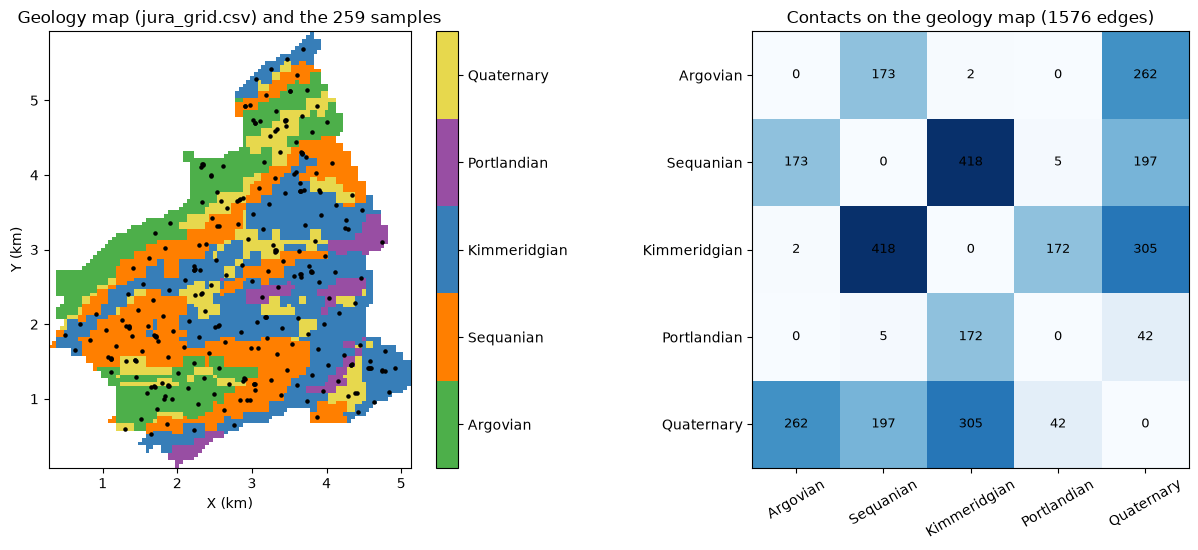

In [3]:
map_contacts = contacts(geo_map)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
show_rock(axes[0], geo_map, "Geology map (jura_grid.csv) and the 259 samples", points=xy)
im = axes[1].imshow(map_contacts.values, cmap="Blues")
axes[1].set_xticks(range(5), NAMES, rotation=30)
axes[1].set_yticks(range(5), NAMES)
for i in range(5):
    for j in range(5):
        axes[1].text(j, i, map_contacts.values[i, j], ha="center", va="center", fontsize=9)
axes[1].set_title(f"Contacts on the geology map ({total_contacts(map_contacts)} edges)")
plt.tight_layout()
plt.show()

The map's contacts follow the geology:

* The Jurassic formations touch only their **stratigraphic neighbours**: Argovian-Sequanian, Sequanian-Kimmeridgian and Kimmeridgian-Portlandian.
* Contacts that skip a formation are almost absent: Argovian-Kimmeridgian 2, Sequanian-Portlandian 5, Argovian-Portlandian 0.
* **Quaternary** deposits touch every formation.

That is exactly the structure of a **hierarchical** truncation rule.

***
## Designing the Truncation Rule

`TruncationRule.hierarchical` puts its first category on $Y_1$ and stacks the others along $Y_2$. With Quaternary first and the formations in stratigraphic order, Quaternary can touch every formation, while each formation can touch only its stratigraphic neighbours. The proportions are those of the 259 samples.

TruncationRule(5 boxes, 2 field(s), {'Quaternary': 0.158, 'Argovian': 0.208, 'Sequanian': 0.259, 'Kimmeridgian': 0.363, 'Portlandian': 0.012})
n_fields: 2


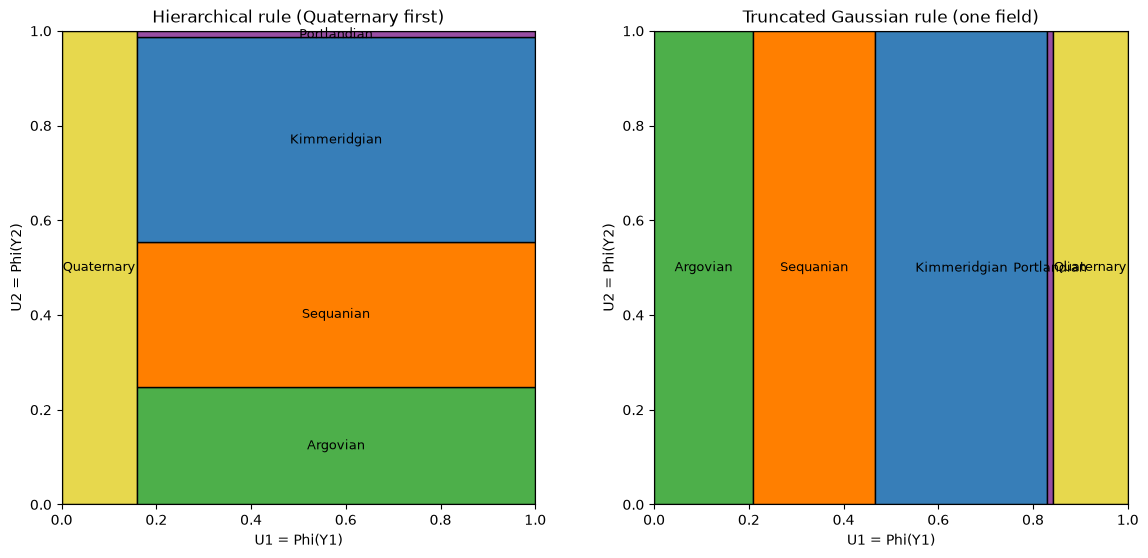

✅ [PASS] rule proportions equal the sample proportions at rho = 0  


In [4]:
p_samples = {c: float((df["rock"] == c).mean()) for c in ["Quaternary"] + STRAT}
rule = TruncationRule.hierarchical(p_samples)
print(rule)
print("n_fields:", rule.n_fields)


def draw_rule(ax, rule, title):
    for cat, a, b, c, d in rule.rectangles:
        ax.add_patch(Rectangle((a, c), b - a, d - c, facecolor=COLORS[cat], edgecolor="k", lw=1))
        ax.text((a + b) / 2, (c + d) / 2, cat, ha="center", va="center", fontsize=9)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel("U1 = Phi(Y1)")
    ax.set_ylabel("U2 = Phi(Y2)")
    ax.set_title(title)
    ax.set_aspect("equal")


rule_tg = TruncationRule.truncated_gaussian({c: p_samples[c] for c in NAMES})
fig, axes = plt.subplots(1, 2, figsize=(12, 5.6))
draw_rule(axes[0], rule, "Hierarchical rule (Quaternary first)")
draw_rule(axes[1], rule_tg, "Truncated Gaussian rule (one field)")
plt.tight_layout()
plt.show()

props = rule.proportions(0.0)
record("rule proportions equal the sample proportions at rho = 0",
       "PASS" if all(abs(props[c] - p_samples[c]) < 1e-9 for c in p_samples) else "FAIL")

The **truncated Gaussian** rule on the right is the one-field alternative, with the categories in the order Argovian, Sequanian, Kimmeridgian, Portlandian, Quaternary. It makes every unit touch only its neighbours in that order, so Quaternary can only border Portlandian. That contradicts the map, and Section 9 shows the consequence.

`from_flag` builds any rule from a small image. The same hierarchical rule, drawn as a flag, gives the same proportions:

In [5]:
q = p_samples["Quaternary"]
rest = np.array([p_samples[c] for c in STRAT]) / (1 - q)
u2_edges = np.concatenate([[0], np.cumsum(rest)])
u2_edges[-1] = 1.0
flag = [["Quaternary"] * 4, STRAT]                 # rows: U1 < q, U1 >= q;  columns: the four U2 bands
rule_flag = TruncationRule.from_flag(flag, u1_edges=[0, q, 1], u2_edges=u2_edges)
pf = rule_flag.proportions(0.0)
print({c: round(v, 4) for c, v in pf.items()})
record("from_flag reproduces the hierarchical rule's proportions",
       "PASS" if all(abs(pf[c] - p_samples[c]) < 1e-9 for c in p_samples) else "FAIL")

{'Quaternary': 0.1583, 'Argovian': 0.2085, 'Sequanian': 0.2587, 'Kimmeridgian': 0.3629, 'Portlandian': 0.0116}
✅ [PASS] from_flag reproduces the hierarchical rule's proportions  


***
## Inferring the Latent Variograms

PGS needs the variograms of the latent fields, which cannot be observed. What can be measured are the **indicator variograms** of the five units at the 259 samples. Section 2.5 gives the model indicator variogram of each unit as a function of the latent correlograms. The latent ranges are fitted by least squares, one field at a time:

* **$Y_1$** alone decides Quaternary versus the rest, so its range $a_1$ is fitted to the Quaternary indicator variogram;
* **$Y_2$** then decides between the formations, so its range $a_2$ is fitted to the four formation indicator variograms, with $a_1$ fixed.

Spherical latent models are used here; Section 11 compares other model types.

fitted in 0.8 s:  Y1 range 0.5 km, Y2 range 1.8 km  (SSE 0.0330)
vario1 = [0.0, 0.0, 0.5, 0.5, 1.0, 'spherical']   vario2 = [0.0, 0.0, 1.8, 1.8, 1.0, 'spherical']


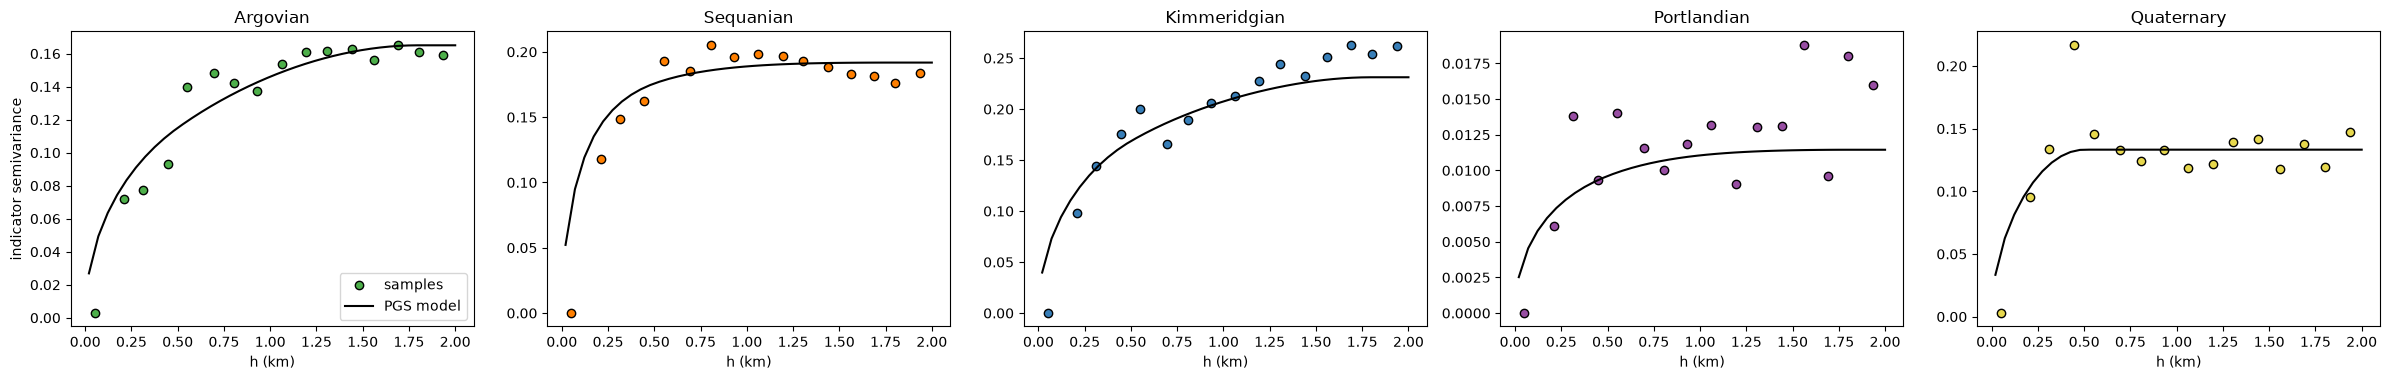

In [6]:
EDGES = np.linspace(0, 2.0, 17)
d_pairs = pdist(xy)
h_lags = np.array([d_pairs[(d_pairs > lo) & (d_pairs <= hi)].mean() for lo, hi in zip(EDGES[:-1], EDGES[1:])])
exp_ind = {}
for c in NAMES:
    i_c = (df["rock"] == c).to_numpy(float)
    g = 0.5 * pdist(i_c[:, None], "sqeuclidean")
    exp_ind[c] = np.array([g[(d_pairs > lo) & (d_pairs <= hi)].mean() for lo, hi in zip(EDGES[:-1], EDGES[1:])])

CORRELOGRAMS = {
    "spherical": lambda h, a: 1 - (1.5 * np.minimum(h / a, 1) - 0.5 * np.minimum(h / a, 1) ** 3),
    "exponential": lambda h, a: np.exp(-3 * h / a),
    "gaussian": lambda h, a: np.exp(-3 * (h / a) ** 2),
}


def both_in(lo, hi, r):
    # P(lo <= X < hi, lo <= X' < hi) for standard normals with correlation r
    lo, hi = max(lo, -8.0), min(hi, 8.0)
    r = min(r, 0.9999)
    mv = multivariate_normal(mean=[0, 0], cov=[[1, r], [r, 1]])
    return mv.cdf([hi, hi]) - mv.cdf([lo, hi]) - mv.cdf([hi, lo]) + mv.cdf([lo, lo])


BOXES = {cat: (a, b, c, d) for cat, a, b, c, d in rule.rectangles}


def model_indicator(cat, a1, a2, h, vtype):
    rho_f = CORRELOGRAMS[vtype]
    u1a, u1b, u2a, u2b = BOXES[cat]
    p_k = (u1b - u1a) * (u2b - u2a)
    out = []
    for hh in h:
        p1 = both_in(ndtri(u1a), ndtri(u1b), rho_f(hh, a1))
        p2 = both_in(ndtri(u2a), ndtri(u2b), rho_f(hh, a2)) if (u2a > 0 or u2b < 1) else 1.0
        out.append(p_k - p1 * p2)
    return np.array(out)


def fit_latent(vtype, cands=np.arange(0.2, 3.01, 0.1)):
    e1 = [np.sum((model_indicator("Quaternary", a, 1.0, h_lags, vtype) - exp_ind["Quaternary"]) ** 2) for a in cands]
    a1 = float(cands[int(np.argmin(e1))])
    e2 = [sum(np.sum((model_indicator(c, a1, a, h_lags, vtype) - exp_ind[c]) ** 2) for c in STRAT) for a in cands]
    a2 = float(cands[int(np.argmin(e2))])
    return round(a1, 2), round(a2, 2), float(min(e1) + min(e2))


t0 = time.perf_counter()
A1, A2, SSE = fit_latent("spherical")
VARIO1 = [0.0, 0.0, A1, A1, 1.0, "spherical"]
VARIO2 = [0.0, 0.0, A2, A2, 1.0, "spherical"]
print(f"fitted in {time.perf_counter() - t0:.1f} s:  Y1 range {A1} km, Y2 range {A2} km  (SSE {SSE:.4f})")
print("vario1 =", VARIO1, "  vario2 =", VARIO2)

hh = np.linspace(0.02, 2.0, 40)
fig, axes = plt.subplots(1, 5, figsize=(24, 3.9))
for ax, c in zip(axes, NAMES):
    ax.plot(h_lags, exp_ind[c], "o", color=COLORS[c], mec="k", label="samples")
    ax.plot(hh, model_indicator(c, A1, A2, hh, "spherical"), "k-", label="PGS model")
    ax.set_title(c)
    ax.set_xlabel("h (km)")
axes[0].set_ylabel("indicator semivariance")
axes[0].legend()
plt.tight_layout()
plt.show()

* **Two scales.** $Y_1$ has a short range (0.5 km): the Quaternary deposits form small, scattered patches. $Y_2$ has a long range (1.8 km): the formations form broad bands.
* **Fit.** The model indicator variograms follow the sample ones for all five units, including the tiny Portlandian sill ($p \approx 0.012$).
* **Fewer parameters than SIS.** In SIS each unit's indicator variogram is fitted on its own. In PGS all five come from two latent ranges through the rule, so they are tied together. That leaves fewer parameters and guarantees a consistent bivariate model, at the price of a less flexible fit to any single unit.

***
## Unconditional Simulation: Latent Fields and Facies

Without data (`df=None`), PGS simulates the two latent fields and classifies them. `return_latent=True` also returns $Y_1$ and $Y_2$. One realization shows the mechanism: $Y_1$ decides where the Quaternary is, and $Y_2$ decides which formation lies everywhere else.

latent-field method: fft


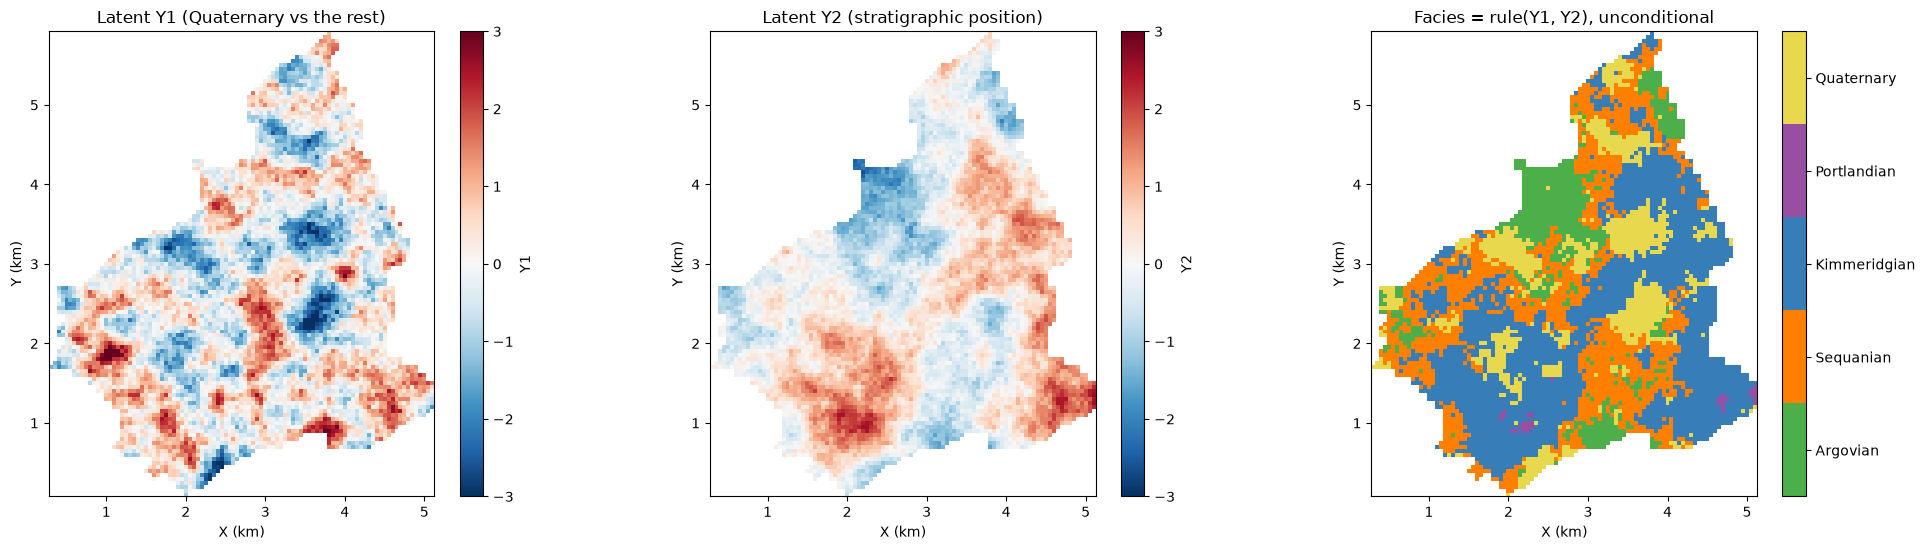

,rule,unconditional (30)
Quaternary,0.158,0.157
Argovian,0.208,0.191
Sequanian,0.259,0.258
Kimmeridgian,0.363,0.383
Portlandian,0.012,0.011


✅ [PASS] unconditional proportions within 0.05 of the rule  max difference 0.020


✅ [PASS] unconditional: no Argovian-Portlandian contacts (not adjacent in the rule)  0 edges


In [7]:
unc = PluriGaussianSimulator(rule, VARIO1, VARIO2).fit(grid)
print("latent-field method:", unc.method_)
codes_u, (y1, y2) = unc.simulate(nsim=30, seed=3, return_latent=True)
labels_u = np.asarray(unc.categories_, dtype=object)[codes_u]

fig, axes = plt.subplots(1, 3, figsize=(21, 5.6))
show_map(axes[0], y1[0], "Latent Y1 (Quaternary vs the rest)", cmap="RdBu_r", vmin=-3, vmax=3, label="Y1")
show_map(axes[1], y2[0], "Latent Y2 (stratigraphic position)", cmap="RdBu_r", vmin=-3, vmax=3, label="Y2")
show_rock(axes[2], labels_u[0], "Facies = rule(Y1, Y2), unconditional")
plt.tight_layout()
plt.show()

pu = category_proportions(codes_u, len(unc.categories_)).mean(0)
target = rule.proportions(0.0)
tab = pd.DataFrame({"rule": [target[c] for c in unc.categories_], "unconditional (30)": pu}, index=unc.categories_)
display(tab.round(3))
record("unconditional proportions within 0.05 of the rule",
       "PASS" if np.abs(tab["rule"] - tab["unconditional (30)"]).max() < 0.05 else "FAIL",
       f"max difference {np.abs(tab['rule'] - tab['unconditional (30)']).max():.3f}")
Mu = contacts(labels_u[0])
record("unconditional: no Argovian-Portlandian contacts (not adjacent in the rule)",
       "PASS" if Mu.loc["Argovian", "Portlandian"] == 0 else "FAIL", f"{Mu.loc['Argovian', 'Portlandian']} edges")

Proportions over 30 unconditional realizations fluctuate around the rule's, as they should: a finite domain does not average a random field perfectly (ergodic fluctuation), especially with $Y_2$'s long range.

***
## Conditional Simulation

`fit(grid, df, "Xloc", "Yloc", "rock")` conditions to the 259 samples. The samples are moved to their nearest 50 m node. Checks:

* the Gibbs latent values at the data fall in their category's region, for every realization;
* the simulated categories at the data nodes equal the data;
* the same seed gives the same realizations, and realization $i$ does not depend on `nsim`: each realization has its own Gibbs chain and latent-field random stream (the chains still run vectorized), so the first 3 of 50 realizations equal an `nsim = 3` run, as with the sequential simulators;
* `pgsim` equals the class.

In [8]:
N_SIM = 50
pgs = PluriGaussianSimulator(rule, VARIO1, VARIO2, gibbs_iter=200)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    pgs.fit(grid, df, "Xloc", "Yloc", "rock")
for w in caught:
    print("warning:", w.message)
t0 = time.perf_counter()
codes = pgs.simulate(nsim=N_SIM, seed=2024)
print(f"{N_SIM} conditional realizations in {time.perf_counter() - t0:.1f} s")
labels = np.asarray(pgs.categories_, dtype=object)[codes]
CATS = pgs.categories_

A, B = pgs.latent_data_
y1d, y2d = A, pgs.rho * A + np.sqrt(1 - pgs.rho ** 2) * B
gibbs_ok = np.all(rule.classify(y1d, y2d) == pgs._data_codes[:, None])
record("Gibbs latent values reproduce the data categories (all realizations)", "PASS" if gibbs_ok else "FAIL",
       f"{len(pgs._data_codes)} data nodes x {N_SIM} realizations")

dist, node_of_data = cKDTree(grid).query(pgs._data_xy)
on_grid = dist < 1e-6                     # data snapped to a lattice node that is part of the grid
cond_ok = np.all(codes[:, node_of_data[on_grid]] == pgs._data_codes[on_grid][None, :])
record("conditional PGS: data categories reproduced at their nodes", "PASS" if cond_ok else "FAIL",
       f"{on_grid.sum()} of {len(on_grid)} data nodes lie on the grid")
# each realization has its own random streams (Gibbs chain and latent fields), so realization i
# depends only on the seed, not on nsim
again = PluriGaussianSimulator(rule, VARIO1, VARIO2).fit(grid, df, "Xloc", "Yloc", "rock").simulate(nsim=N_SIM, seed=2024)
record("conditional PGS: same seed and nsim -> identical", "PASS" if np.array_equal(again, codes) else "FAIL")
first3 = PluriGaussianSimulator(rule, VARIO1, VARIO2).fit(grid, df, "Xloc", "Yloc", "rock").simulate(nsim=3, seed=2024)
record(f"conditional PGS: nsim = 3 equals the first 3 of nsim = {N_SIM} (same seed)",
       "PASS" if np.array_equal(first3, codes[:3]) else "FAIL", f"{np.mean(first3 != codes[:3]):.0%} of nodes differ")
one_call = pgsim(grid, df, "Xloc", "Yloc", "rock", rule, VARIO1, VARIO2, nsim=N_SIM, seed=2024, labels=True)
record("pgsim(labels=True) == class realizations", "PASS" if np.array_equal(one_call, labels) else "FAIL")

50 conditional realizations in 4.5 s
✅ [PASS] Gibbs latent values reproduce the data categories (all realizations)  218 data nodes x 50 realizations
✅ [PASS] conditional PGS: data categories reproduced at their nodes  218 of 218 data nodes lie on the grid


✅ [PASS] conditional PGS: same seed and nsim -> identical  


✅ [PASS] conditional PGS: nsim = 3 equals the first 3 of nsim = 50 (same seed)  0% of nodes differ


✅ [PASS] pgsim(labels=True) == class realizations  


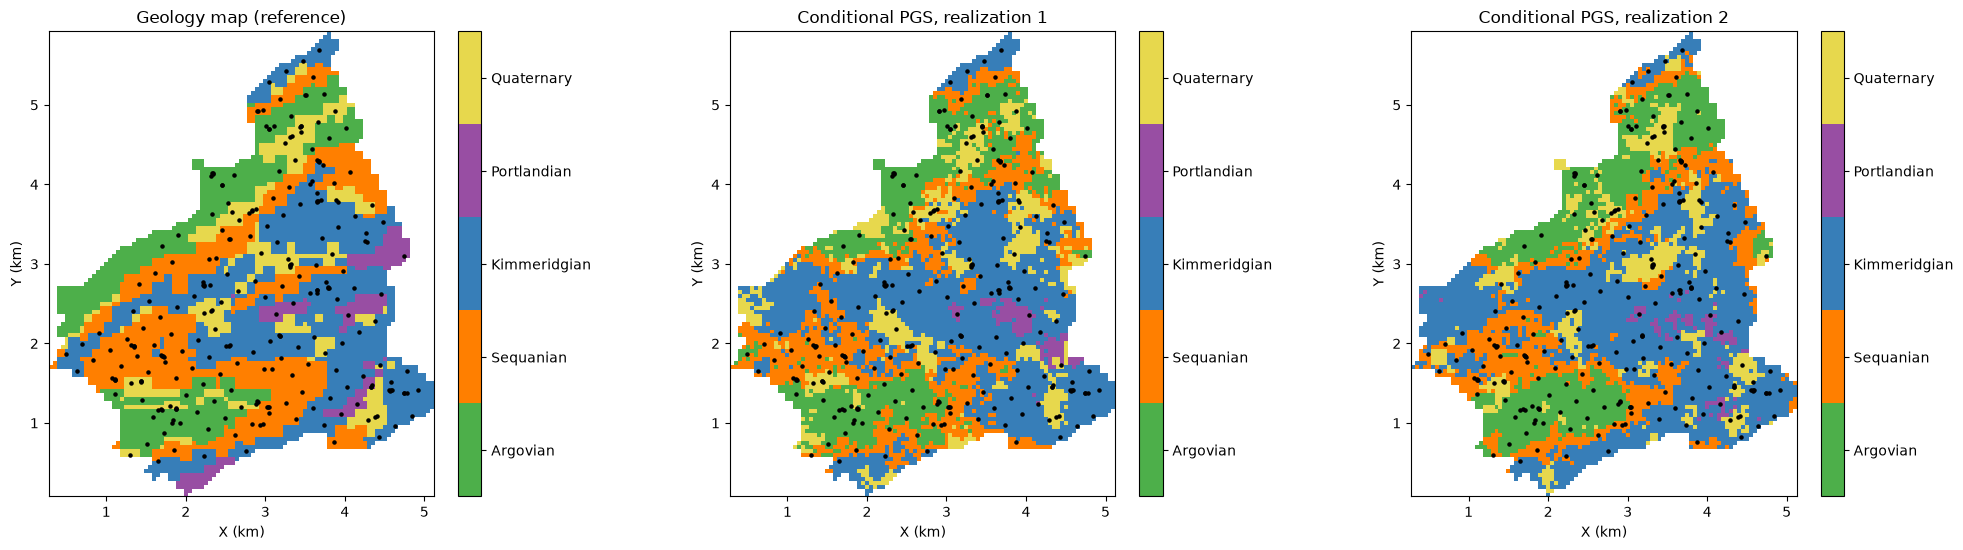

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(21, 5.6))
show_rock(axes[0], geo_map, "Geology map (reference)", points=xy)
show_rock(axes[1], labels[0], "Conditional PGS, realization 1", points=xy)
show_rock(axes[2], labels[1], "Conditional PGS, realization 2", points=xy)
plt.tight_layout()
plt.show()

***
## Contacts: PGS vs Truncated Gaussian vs SIS

Three categorical simulators, all conditioned to the same 259 samples, are compared:

* **PGS, hierarchical rule** (the realizations above);
* **truncated Gaussian:** one latent field, with the rule in the order Argovian, Sequanian, Kimmeridgian, Portlandian, Quaternary, and a single latent variogram (the $Y_2$ fit);
* **SIS** (`IndicatorCoSimulator`, categorical), with spherical indicator variograms fitted to each unit's experimental indicator variogram, as in the [SIS notebook](05_07_04_sicosim.ipynb).

The contact matrices are averaged over 10 realizations.

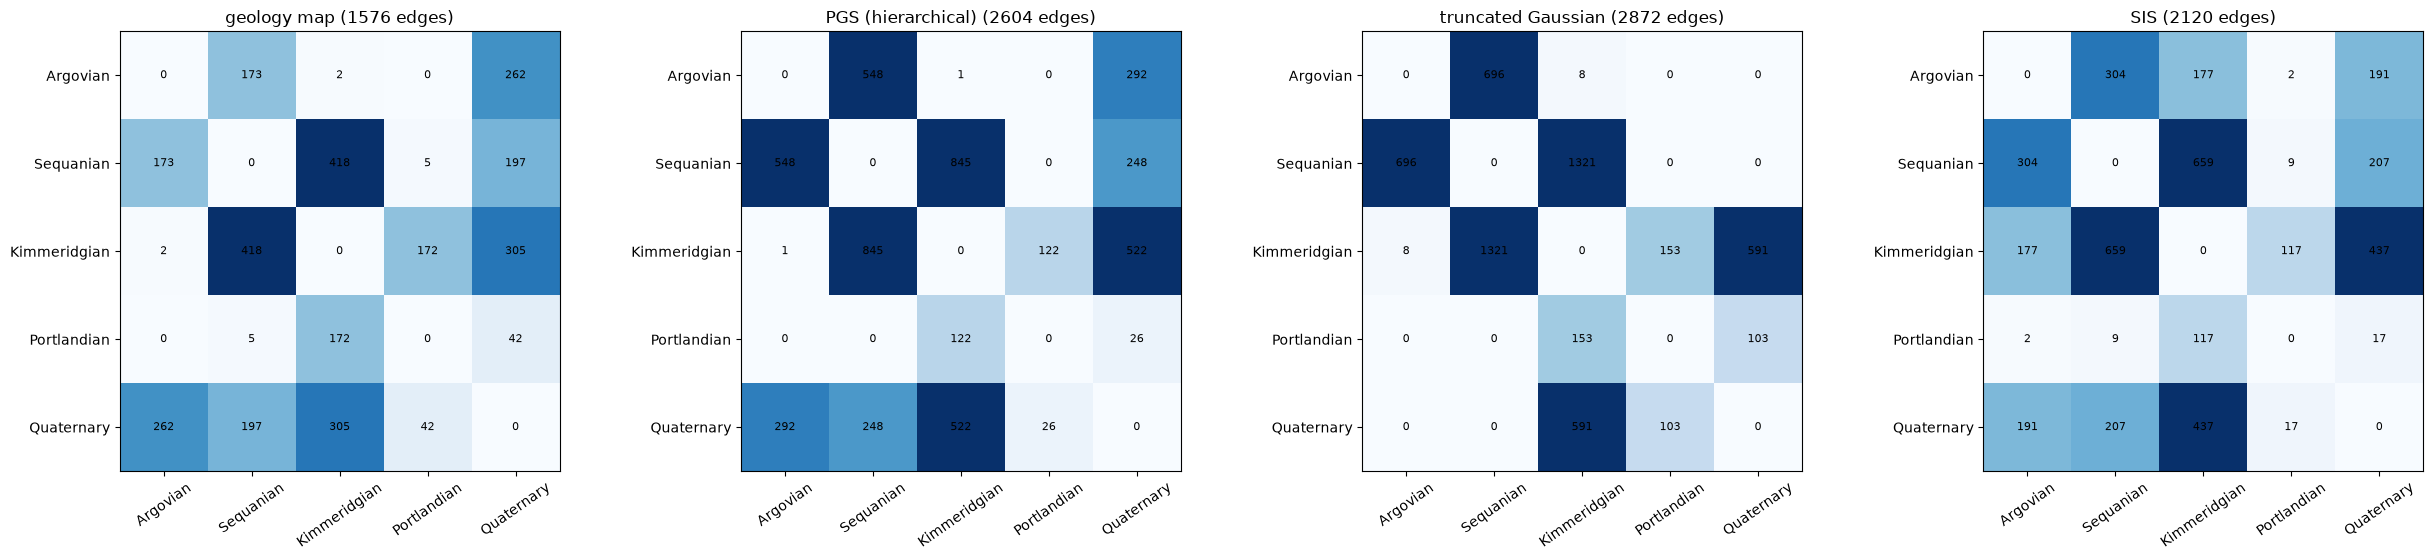

,total contact edges,Argo-Kimm,Sequ-Port,Argo-Port,Quaternary-Argovian,share of non-stratigraphic contacts
method,,,,,,
geology map,1576.0,2.0,5.0,0.0,262.0,0.004
PGS (hierarchical),2604.5,1.4,0.0,0.0,291.8,0.001
truncated Gaussian,2872.1,7.5,0.0,0.0,0.0,0.003
SIS,2119.8,177.4,9.0,2.5,190.8,0.089


✅ [PASS] PGS keeps non-stratigraphic contacts below 1% (map: ~0.4%)  PGS 0.054%, SIS 8.9%


In [10]:
tg = PluriGaussianSimulator(rule_tg, VARIO2).fit(grid, df, "Xloc", "Yloc", "rock")
labels_tg = np.asarray(tg.categories_, dtype=object)[tg.simulate(nsim=N_SIM, seed=2024)]


def fit_indicator_vario(ind):
    p = ind.mean()
    sill = p * (1 - p)
    g = 0.5 * pdist(ind[:, None], "sqeuclidean")
    e = np.array([g[(d_pairs > lo) & (d_pairs <= hi)].mean() for lo, hi in zip(EDGES[:-1], EDGES[1:])])
    sph = lambda h, nr, a: nr * sill + (sill - nr * sill) * (1.5 * np.minimum(h / a, 1) - 0.5 * np.minimum(h / a, 1) ** 3)
    (nr, a), _ = curve_fit(sph, h_lags, e, p0=[0.2, 1.0], bounds=([0, 0.1], [0.95, 4]))
    return [0.0, round(nr * sill, 4), round(a, 3), round(a, 3), round(sill, 4), "spherical"]


sis_codes = {n: i + 1 for i, n in enumerate(NAMES)}
df["rock_code"] = df["rock"].map(sis_codes)
sis_varios = {k: fit_indicator_vario((df["rock"] == n).to_numpy(float)) for n, k in sis_codes.items()}
sis = IndicatorCoSimulator(list(sis_codes.values()), sis_varios, num_points=16, radius=1.5, use_gpu=USE_GPU)
labels_sis = np.asarray(NAMES, dtype=object)[sis.fit(grid, df, "Xloc", "Yloc", "rock_code").simulate(
    nsim=N_SIM, seed=2024).astype(int) - 1]

methods = {"PGS (hierarchical)": labels, "truncated Gaussian": labels_tg, "SIS": labels_sis}
avg_contacts = {k: sum(contacts(v[r]) for r in range(10)) / 10 for k, v in methods.items()}

fig, axes = plt.subplots(1, 4, figsize=(25, 5.6))
for ax, (name, M) in zip(axes, [("geology map", map_contacts)] + list(avg_contacts.items())):
    ax.imshow(M.values, cmap="Blues", vmin=0, vmax=max(map_contacts.values.max(), 1))
    ax.set_xticks(range(5), NAMES, rotation=35)
    ax.set_yticks(range(5), NAMES)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f"{M.values[i, j]:.0f}", ha="center", va="center", fontsize=8)
    ax.set_title(f"{name} ({total_contacts(M.round())} edges)")
plt.tight_layout()
plt.show()

FORBIDDEN = [("Argovian", "Kimmeridgian"), ("Sequanian", "Portlandian"), ("Argovian", "Portlandian")]
rows = []
for name, M in [("geology map", map_contacts)] + list(avg_contacts.items()):
    tot = M.values.sum() / 2
    rows.append({"method": name, "total contact edges": tot,
                 **{f"{a[:4]}-{b[:4]}": M.loc[a, b] for a, b in FORBIDDEN},
                 "Quaternary-Argovian": M.loc["Quaternary", "Argovian"],
                 "share of non-stratigraphic contacts": sum(M.loc[a, b] for a, b in FORBIDDEN) / tot})
contact_table = pd.DataFrame(rows).set_index("method")
display(contact_table.round(3))
ct = contact_table["share of non-stratigraphic contacts"]
record("PGS keeps non-stratigraphic contacts below 1% (map: ~0.4%)", "PASS" if ct["PGS (hierarchical)"] < 0.01 else "FAIL",
       f"PGS {ct['PGS (hierarchical)']:.3%}, SIS {ct['SIS']:.1%}")

* **PGS reproduces the geology.** Contacts that skip a formation make up 0.05% of all PGS contacts, against 0.4% on the map. The forbidden pairs are almost absent: about 1.4 Argovian-Kimmeridgian edges per realization, where a narrow Sequanian band is skipped between two neighbouring cells. Quaternary touches every formation, as on the map; for example, 292 edges with Argovian against the map's 262.
* **SIS ignores the stratigraphy.** About 9% of its contacts skip a formation: 177 Argovian-Kimmeridgian edges per realization against the map's 2, plus Argovian-Portlandian contacts that never occur on the map.
* **The wrong rule gives the wrong geology.** The truncated Gaussian rule respects its own order, so it also has few skipped formations. But it forbids Quaternary next to Argovian, Sequanian and most of Kimmeridgian, so it has zero Quaternary-Argovian edges against 262 on the map. The rule has to come from the geology, and a one-field rule cannot express "one unit touches all".
* **Boundary length.** All three simulators produce more contact edges than the map (PGS about 2,600, SIS about 2,100, map 1,576). The realizations are more fragmented than a hand-drawn map, which generalizes boundaries; Section 11 shows how the latent model type controls this.

***
## Validation against the Geology Map and Held-Out Samples

Cell-by-cell agreement with the geology map, unit proportions, and two scores at the 100 held-out samples, each read at its nearest node:

* the **mean probability** given to the sample's recorded unit;
* the **multiclass Brier score**, $\frac1n \sum_i \sum_k (p_{ik} - o_{ik})^2$.

Keep in mind that the field classification at the samples and the map disagree at about 15% of the sites.

In [11]:
node_test = cKDTree(grid).query(xy_test)[1]
truth_test = test["rock"].to_numpy(dtype=object)
rows = []
for name, lab in methods.items():
    probs = np.stack([(lab == c).mean(0) for c in NAMES])            # (5, n_nodes)
    mode = np.asarray(NAMES, dtype=object)[probs.argmax(0)]
    pt = probs[:, node_test]
    onehot = np.stack([(truth_test == c).astype(float) for c in NAMES])
    rows.append({"method": name, "agreement per realization": np.mean(lab == geo_map),
                 "agreement, most probable unit": np.mean(mode == geo_map),
                 "held-out: P(recorded unit)": np.mean([pt[NAMES.index(t), i] for i, t in enumerate(truth_test)]),
                 "held-out: Brier": np.mean(((pt - onehot) ** 2).sum(0)),
                 **{f"prop. {c}": np.mean(lab == c) for c in NAMES}})
rows.append({"method": "geology map", **{f"prop. {c}": np.mean(geo_map == c) for c in NAMES}})
rows.append({"method": "samples (259)", **{f"prop. {c}": p_samples[c] for c in NAMES}})
val_table = pd.DataFrame(rows).set_index("method")
display(val_table.round(3))

,agreement per realization,"agreement, most probable unit",held-out: P(recorded unit),held-out: Brier,prop. Argovian,prop. Sequanian,prop. Kimmeridgian,prop. Portlandian,prop. Quaternary
method,,,,,,,,,
PGS (hierarchical),0.576,0.691,0.720,0.279,0.202,0.236,0.415,0.014,0.134
truncated Gaussian,0.531,0.632,0.693,0.320,0.173,0.275,0.450,0.012,0.090
SIS,0.595,0.710,0.711,0.267,0.201,0.241,0.411,0.019,0.128
geology map,NaN,NaN,NaN,NaN,0.199,0.273,0.342,0.053,0.133
samples (259),NaN,NaN,NaN,NaN,0.208,0.259,0.363,0.012,0.158


* **Cell-wise accuracy is similar.** PGS and SIS agree with the map about equally well: 58% vs 60% per realization, and 69% vs 71% for the most probable unit. At the held-out samples, PGS gives the recorded unit a mean probability of 0.72 against 0.71 for SIS, and the multiclass Brier scores are 0.28 vs 0.27. The truncated Gaussian rule is worst on every score.
* **The advantage of PGS is structural, not cell-wise.** Its realizations have the right *kinds* of boundaries (Section 9). Contacts govern, for example, flow and transport across unit boundaries, or soil-forming parent material along a transect, and there PGS gives plausible answers that SIS cannot.
* **Proportions.** Both PGS and SIS over-produce Kimmeridgian (about 0.42) relative to the samples (0.36) and the map (0.34). For PGS, this comes from conditioning on 259 data with a long-range $Y_2$ field: the domain holds only a few $Y_2$ ranges, so the proportions of a realization fluctuate around the rule's (the unconditional runs in Section 7 already showed Kimmeridgian at 0.38). If exact proportions matter, check them on the realizations and adjust the rule.

***
## Choosing the Latent Variogram Type

The latent ranges were fitted for spherical correlograms. The **type** of latent model also matters, because it sets how rough the boundaries between units are. Spherical and exponential correlograms are linear at the origin, which gives rough, fragmented boundaries; the Gaussian correlogram is parabolic at the origin, which gives smooth boundaries. Each type is fitted to the indicator variograms as above and then simulated (20 realizations each).

,a1 (km),a2 (km),indicator-variogram SSE,total contact edges,Argo-Kimm edges,agreement with map
latent type,,,,,,
spherical,0.5,1.8,0.0330,2695.8,0.6,0.5761
exponential,0.6,2.6,0.0463,3146.0,3.8,0.5535
gaussian,0.4,1.2,0.0197,1931.0,32.8,0.5199
geology map,NaN,NaN,NaN,1576.0,2.0,NaN


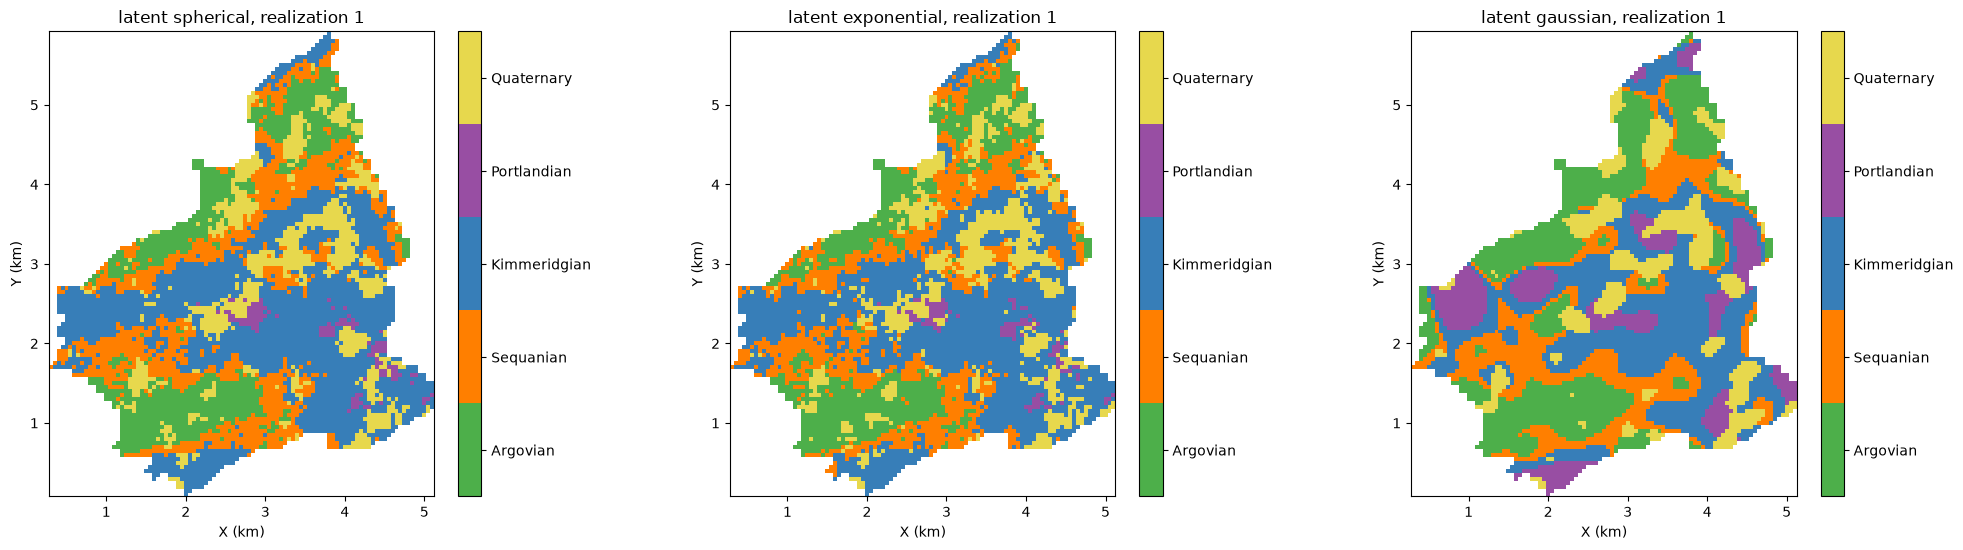

In [12]:
rows = []
type_labels = {}
for vtype in ["spherical", "exponential", "gaussian"]:
    a1, a2, sse = fit_latent(vtype)
    sim = PluriGaussianSimulator(rule, [0, 0, a1, a1, 1, vtype], [0, 0, a2, a2, 1, vtype]).fit(
        grid, df, "Xloc", "Yloc", "rock")
    lab = np.asarray(sim.categories_, dtype=object)[sim.simulate(nsim=20, seed=7)]
    type_labels[vtype] = lab
    Ms = [contacts(lab[r]) for r in range(5)]
    rows.append({"latent type": vtype, "a1 (km)": a1, "a2 (km)": a2, "indicator-variogram SSE": sse,
                 "total contact edges": np.mean([total_contacts(M) for M in Ms]),
                 "Argo-Kimm edges": np.mean([M.loc["Argovian", "Kimmeridgian"] for M in Ms]),
                 "agreement with map": np.mean(lab == geo_map)})
rows.append({"latent type": "geology map", "total contact edges": total_contacts(map_contacts),
             "Argo-Kimm edges": map_contacts.loc["Argovian", "Kimmeridgian"]})
type_table = pd.DataFrame(rows).set_index("latent type")
display(type_table.round(4))

fig, axes = plt.subplots(1, 3, figsize=(21, 5.6))
for ax, vtype in zip(axes, ["spherical", "exponential", "gaussian"]):
    show_rock(ax, type_labels[vtype][0], f"latent {vtype}, realization 1")
plt.tight_layout()
plt.show()

The model type changes the realizations more than the fit suggests:

* **Gaussian latent correlograms fit the indicator variograms best** (lowest SSE). They give the smoothest boundaries, about 1,930 edges, closest to the map's 1,576. But they produce about 33 Argovian-Kimmeridgian edges per realization, and the lowest agreement with the map (0.52). Very smooth fields kriged to dense data develop steep local gradients, which jump across the narrow Sequanian band between neighbouring cells.
* **Exponential** gives the roughest units (about 3,150 edges) and the worst fit.
* **Spherical** is the compromise used here: the best agreement with the map and almost no forbidden contacts.

The lesson is the same as in the earlier notebooks: a good fit to two-point statistics does not guarantee realistic realizations. Check the realizations on what matters (contacts, boundary roughness, agreement) before choosing.

***
## Correlated Latent Fields: the Effect of $\rho$

With $\rho \ne 0$, $Y_2$ shares part of $Y_1$. In this rule $Y_1$ decides Quaternary versus the rest, so a correlation links **where the Quaternary is** with **which formation is nearby**. For $\rho > 0$, high $Y_1$ (no Quaternary) goes with high $Y_2$ (younger formations), so Quaternary deposits tend to border the *older* formations.

The same rectangles also give different proportions for $\rho \ne 0$ (`rule.proportions(rho)`). Unconditional realizations show the effect without data.

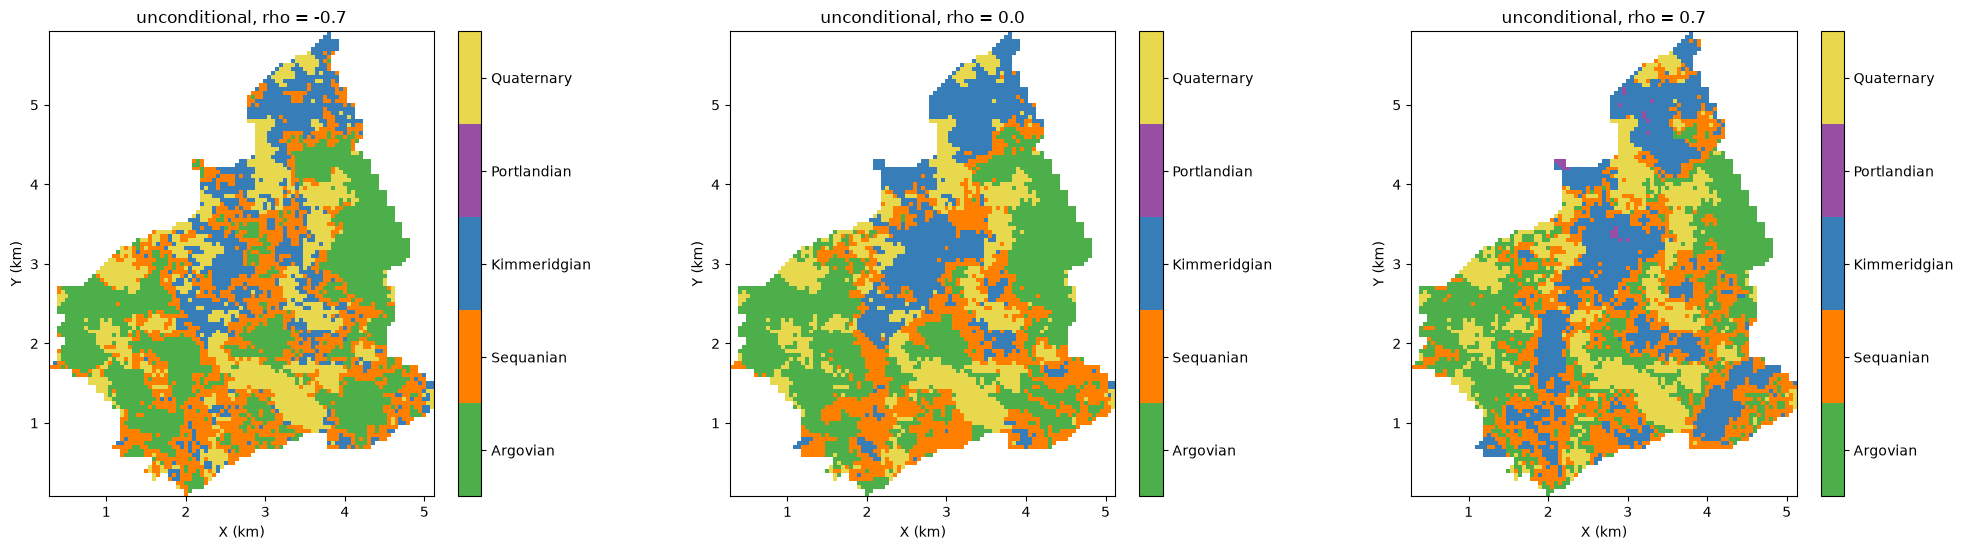

rho,-0.7,0.0,0.7
rule p(Quaternary),0.158,0.158,0.158
rule p(Argovian),0.246,0.208,0.139
rule p(Sequanian),0.291,0.259,0.267
rule p(Kimmeridgian),0.303,0.363,0.422
rule p(Portlandian),0.002,0.012,0.014
Quat. contacts with Argovian (share),0.075,0.285,0.449
Quat. contacts with Sequanian (share),0.337,0.377,0.403
Quat. contacts with Kimmeridgian (share),0.586,0.334,0.148
Quat. contacts with Portlandian (share),0.002,0.004,0.000


In [13]:
rows = []
fig, axes = plt.subplots(1, 3, figsize=(21, 5.6))
for ax, rho in zip(axes, [-0.7, 0.0, 0.7]):
    sim = PluriGaussianSimulator(rule, VARIO1, VARIO2, rho=rho).fit(grid)
    lab = np.asarray(sim.categories_, dtype=object)[sim.simulate(nsim=20, seed=11)]
    show_rock(ax, lab[0], f"unconditional, rho = {rho}")
    M = sum(contacts(lab[r]) for r in range(5)) / 5
    q_edges = M.loc["Quaternary", STRAT]
    rows.append({"rho": rho, **{f"rule p({c})": v for c, v in rule.proportions(rho).items()},
                 **{f"Quat. contacts with {c} (share)": q_edges[c] / q_edges.sum() for c in STRAT}})
plt.tight_layout()
plt.show()
pd.DataFrame(rows).set_index("rho").round(3).T

* **Proportions change with $\rho$.** The same rectangles give different proportions: Argovian 0.25, 0.21 and 0.14 for $\rho = -0.7$, 0 and 0.7. A rule meant for $\rho \ne 0$ has to be re-calibrated so that `rule.proportions(rho)` matches the targets.
* **Quaternary placement changes with $\rho$.**
    * $\rho = 0.7$: Quaternary borders mostly the old formations (45% of its contacts with Argovian, 15% with Kimmeridgian).
    * $\rho = -0.7$: it borders mostly the younger ones (59% Kimmeridgian, 8% Argovian).
* **The map supports $\rho = 0$.** On the map the shares are 33% Argovian, 24% Sequanian, 38% Kimmeridgian and 5% Portlandian, closest to $\rho = 0$ (29%, 38%, 33%, 0.4%). So $\rho = 0$ is the right choice here.

In other settings $\rho$ encodes real geology, such as cover sediments that preferentially overlie one part of a sequence.

***
## Visualization of Uncertainty

### Animated display of realizations

20 conditional PGS realizations in sequence. Units near dense samples barely change; boundaries far from samples move.

In [14]:
N_FRAMES = 20
plt.rcParams["animation.embed_limit"] = 50
fig_anim, ax_anim = plt.subplots(figsize=(7.2, 7.6))
codes_img = lambda lab: to_image(np.array([NAMES.index(v) for v in lab], float))
im_anim = ax_anim.imshow(codes_img(labels[0]), origin="lower", extent=EXTENT, cmap=CMAP, vmin=-0.5, vmax=4.5,
                         interpolation="nearest")
ax_anim.scatter(xy[:, 0], xy[:, 1], s=4, c="k")
cb = plt.colorbar(im_anim, ax=ax_anim, ticks=range(5), fraction=0.046, pad=0.04)
cb.ax.set_yticklabels(NAMES)
ax_anim.set_xlabel("X (km)")
ax_anim.set_ylabel("Y (km)")
title_anim = ax_anim.set_title(f"Conditional PGS, realization 1 / {N_FRAMES}")


def _update(frame):
    im_anim.set_data(codes_img(labels[frame]))
    title_anim.set_text(f"Conditional PGS, realization {frame + 1} / {N_FRAMES}")
    return im_anim, title_anim


anim = FuncAnimation(fig_anim, _update, frames=N_FRAMES, interval=500, blit=False, repeat=True)
plt.close(fig_anim)
display(HTML(anim.to_jshtml()))

### Probability and entropy maps

`category_probabilities(codes)` gives, for each unit, the fraction of realizations in which each node belongs to it. The **entropy** $H(\mathbf{u}) = -\sum_k p_k \log p_k$ (in nats; at most $\log 5 \approx 1.61$) summarizes the uncertainty in one map: 0 where every realization agrees, high where several units are equally likely.

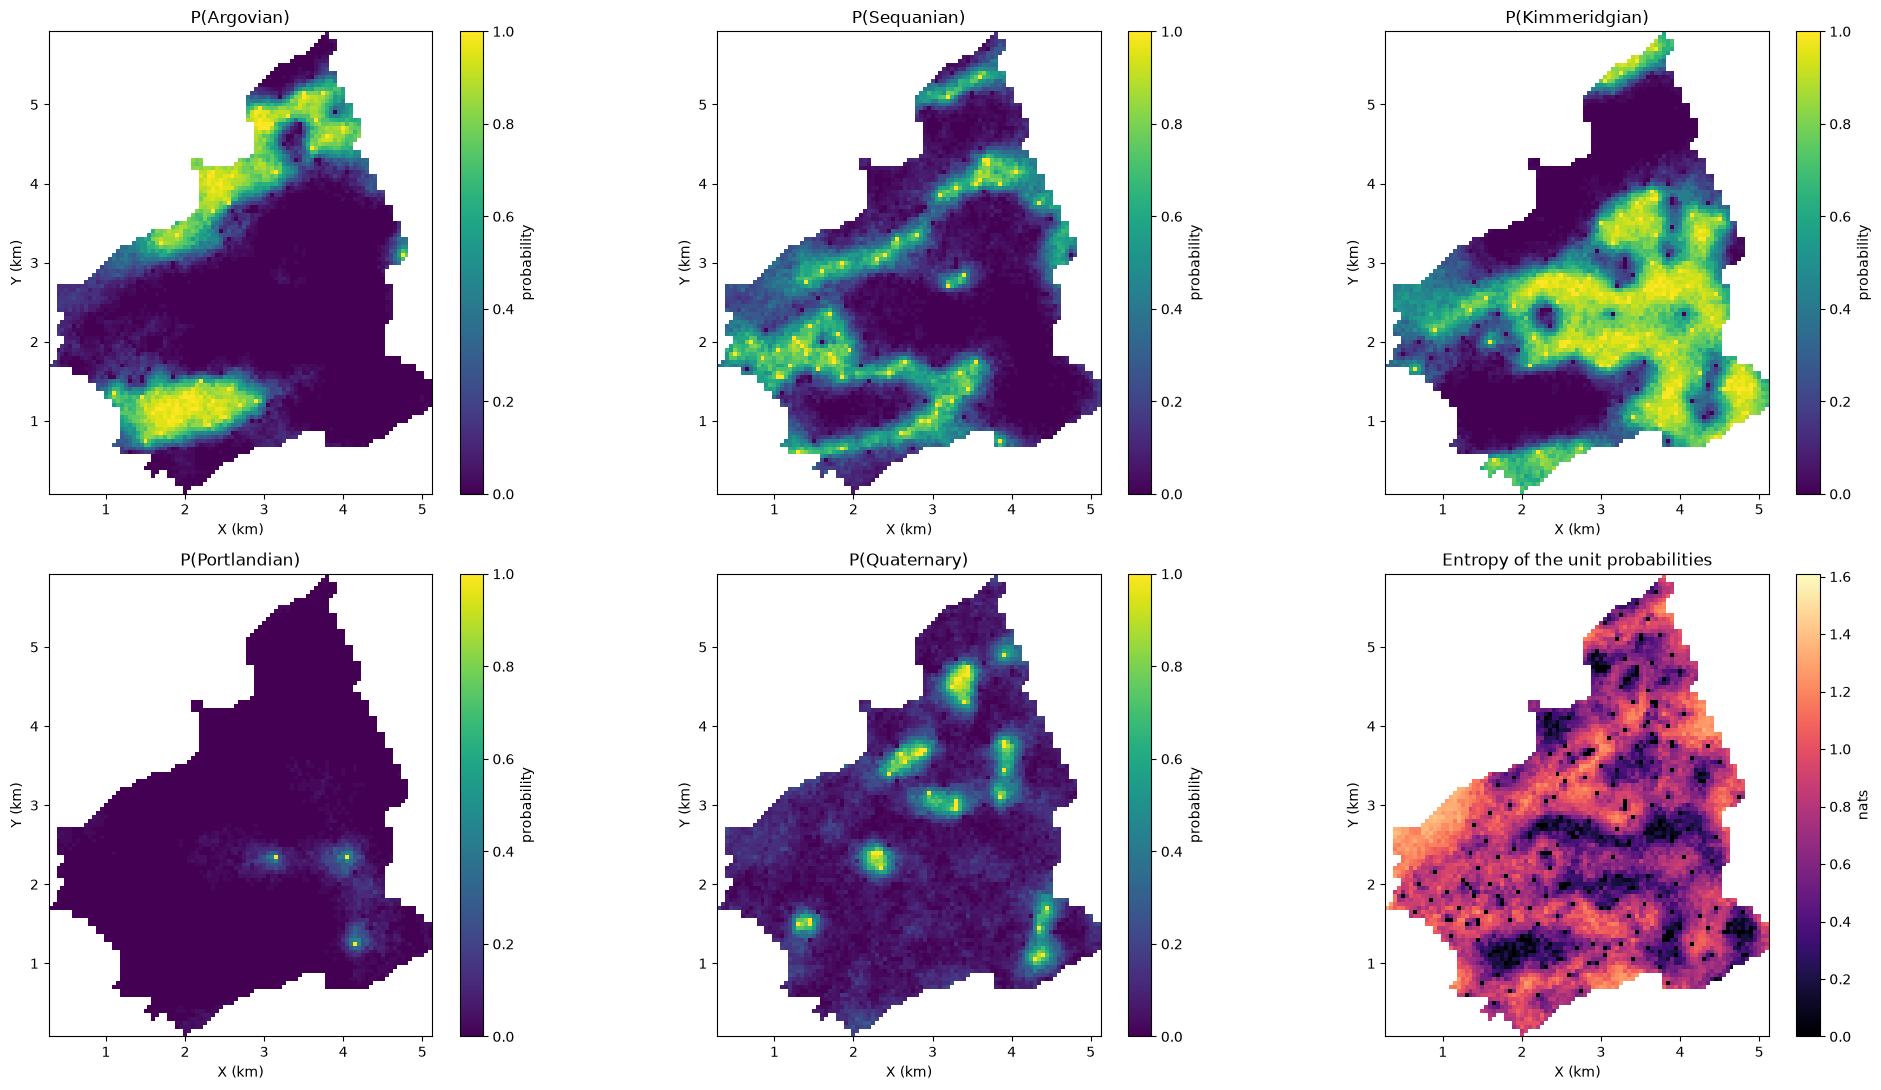

mean entropy 0.70 nats; nodes with a unit at P > 0.9: 14%


In [15]:
P = category_probabilities(codes, len(CATS))                      # (5, n_nodes), in rule order
H = -(np.where(P > 0, P * np.log(np.where(P > 0, P, 1)), 0)).sum(0)
fig, axes = plt.subplots(2, 3, figsize=(21, 11))
for ax, c in zip(axes.flat[:5], NAMES):
    show_map(ax, P[CATS.index(c)], f"P({c})", cmap="viridis", vmin=0, vmax=1, label="probability")
show_map(axes.flat[5], H, "Entropy of the unit probabilities", cmap="magma", vmin=0, vmax=np.log(5), label="nats")
plt.tight_layout()
plt.show()
print(f"mean entropy {H.mean():.2f} nats; nodes with a unit at P > 0.9: {np.mean(P.max(0) > 0.9):.0%}")

***
## Run Time

The cost has two parts: the Gibbs sampler (`gibbs_iter` sweeps over the data, vectorized over realizations) and the latent-field simulation (FFT on the lattice, or turning bands with `method="tb"`). Timings on the 5,957-node grid with 259 data:

In [16]:
rows = []
for label, kw, nsim in [("FFT, 200 Gibbs sweeps", dict(), 1), ("FFT, 200 Gibbs sweeps", dict(), 50),
                        ("FFT, 50 Gibbs sweeps", dict(gibbs_iter=50), 50),
                        ("turning bands (500 lines)", dict(method="tb", nlines=500), 10)]:
    sim = PluriGaussianSimulator(rule, VARIO1, VARIO2, **kw).fit(grid, df, "Xloc", "Yloc", "rock")
    t0 = time.perf_counter()
    c_ = sim.simulate(nsim=nsim, seed=1)
    sec = time.perf_counter() - t0
    rows.append({"configuration": label, "nsim": nsim, "seconds": sec, "seconds / realization": sec / nsim,
                 "agreement with map": np.mean(np.asarray(sim.categories_, dtype=object)[c_] == geo_map)})
pd.DataFrame(rows).set_index("configuration").round(3)

,nsim,seconds,seconds / realization,agreement with map
configuration,,,,
"FFT, 200 Gibbs sweeps",1,3.707,3.707,0.578
"FFT, 200 Gibbs sweeps",50,4.511,0.090,0.578
"FFT, 50 Gibbs sweeps",50,1.404,0.028,0.578
turning bands (500 lines),10,5.512,0.551,0.582


* **The Gibbs sampler dominates** for few realizations: one realization takes about 4 s, almost all of it in 200 sweeps over the 218 data nodes.
* **Many realizations are almost free.** Because the chains are vectorized over realizations, 50 realizations take about 5 s in total, 0.1 s each.
* **Fewer Gibbs sweeps** (50) cut that to 1.5 s with no visible change in agreement. Check convergence (for example, stable data-node latent statistics) before reducing `gibbs_iter` on other data.
* **Turning bands**, needed on irregular grids, costs about 0.6 s per realization for the latent fields on this grid.

***
## Summary and Conclusions

In [17]:
pd.DataFrame(RESULTS)

,Feature,Status,Notes
0,rule proportions equal the sample proportions ...,PASS,
1,from_flag reproduces the hierarchical rule's p...,PASS,
2,unconditional proportions within 0.05 of the rule,PASS,max difference 0.020
3,unconditional: no Argovian-Portlandian contact...,PASS,0 edges
4,Gibbs latent values reproduce the data categor...,PASS,218 data nodes x 50 realizations
5,conditional PGS: data categories reproduced at...,PASS,218 of 218 data nodes lie on the grid
6,conditional PGS: same seed and nsim -> identical,PASS,
7,conditional PGS: nsim = 3 equals the first 3 o...,PASS,0% of nodes differ
8,pgsim(labels=True) == class realizations,PASS,
9,PGS keeps non-stratigraphic contacts below 1% ...,PASS,"PGS 0.054%, SIS 8.9%"


- **Plurigaussian simulation** turns one or two latent Gaussian fields into categories with a truncation rule. The rule decides which units may touch; the latent variograms decide their size and shape.
- **The Jura geology map** showed stratigraphic contacts (Argovian-Sequanian-Kimmeridgian-Portlandian) with Quaternary touching all of them. A **hierarchical rule**, with Quaternary on $Y_1$ and the formations stacked on $Y_2$, encodes exactly that. `from_flag` builds the same rule from an image.
- **Latent variograms** were inferred from the indicator variograms of 259 samples through the rule: 0.5 km for $Y_1$ (Quaternary patches) and 1.8 km for $Y_2$ (formation bands).
- **Conditioning:** the Gibbs sampler gave latent values consistent with every datum's category in every realization, and the conditional realizations reproduce the data. Realization $i$ depends only on the seed, not on `nsim`.
- **Contacts:** PGS kept non-stratigraphic contacts at 0.05% (map 0.4%), while SIS had 9%, including 177 Argovian-Kimmeridgian edges per realization against the map's 2. A one-field truncated Gaussian rule could not let Quaternary touch Argovian at all. Cell-wise agreement with the map and held-out scores were similar for PGS and SIS. The gain from PGS is geological structure.
- **Model choice:** the Gaussian latent model fitted the indicator variograms best but produced worse realizations. Check realizations, not just the fit. $\rho$ changes both proportions and which formations the Quaternary borders, and the map supports $\rho = 0$.
- **Cost:** about 4 s for the first realization (Gibbs sampling), then about 0.1 s per additional realization with FFT latent fields.

| Object | Role in this notebook |
|---|---|
| `TruncationRule.hierarchical` | Quaternary on $Y_1$; formations stacked in stratigraphic order on $Y_2$ |
| `TruncationRule.truncated_gaussian` | One-field alternative (wrong contacts for this geology) |
| `TruncationRule.from_flag` | The same hierarchical rule, drawn as a flag image |
| `PluriGaussianSimulator` | Gibbs conditioning, FFT / turning-bands latent fields, `return_latent`, `latent_data_` |
| `pgsim` | One-call PGS with category labels |
| `category_probabilities`, `category_proportions` | Probability, entropy and proportion summaries |
| `IndicatorCoSimulator` | SIS comparison |

### Choosing the options

| Situation | Choice |
|---|---|
| Units with known contact relations (stratigraphy, depositional sequences, soil catenas) | PGS with a rule that encodes them; measure contacts on a map or in wells first |
| One unit that can touch all others (cover, intrusion, erosion surface) plus an ordered sequence | `TruncationRule.hierarchical`, with that unit first |
| A purely ordered sequence | `TruncationRule.truncated_gaussian` (one field) |
| Any other adjacency pattern | `TruncationRule.from_flag` |
| Latent variograms | fit to the indicator variograms through the rule; then check contacts and boundary roughness on realizations before choosing the model type |
| Linked placement of units (e.g. cover preferring old formations) | $\rho \ne 0$; re-derive proportions with `rule.proportions(rho)` |
| No contact constraints, class-wise indicator variograms matter most | SIS may suffice |

***
## References

| Reference | Used for |
|---|---|
| Matheron, G., Beucher, H., de Fouquet, C., Galli, A., Guérillot, D. & Ravenne, C. (1987). Conditional simulation of the geometry of fluvio-deltaic reservoirs. SPE 16753. | Truncated Gaussian simulation |
| Le Loc'h, G. & Galli, A. (1997). Truncated plurigaussian method: theoretical and practical points of view. In Baafi, E.Y. & Schofield, N.A. (eds.), *Geostatistics Wollongong '96*, 211-222. Kluwer. | Plurigaussian simulation |
| Armstrong, M., Galli, A., Beucher, H., Le Loc'h, G., Renard, D., Doligez, B., Eschard, R. & Geffroy, F. (2003; 2nd ed. 2011). *Plurigaussian Simulations in Geosciences*. Springer. | Truncation rules, variogram inference, Gibbs conditioning |
| Emery, X. (2007). Simulation of geological domains using the plurigaussian model: new developments and computer programs. *Computers & Geosciences* 33, 1189-1201. | Gibbs sampler for conditioning |
| Geman, S. & Geman, D. (1984). Stochastic relaxation, Gibbs distributions, and the Bayesian restoration of images. *IEEE Transactions on Pattern Analysis and Machine Intelligence* 6, 721-741. | The Gibbs sampler |
| Dietrich, C.R. & Newsam, G.N. (1993). A fast and exact method for multidimensional Gaussian stochastic simulations. *Water Resources Research* 29, 2861-2869. | FFT simulation of the latent fields |
| Atteia, O., Dubois, J.-P. & Webster, R. (1994). Geostatistical analysis of soil contamination in the Swiss Jura. *Environmental Pollution* 86, 315-327. | The Jura data |
| Goovaerts, P. (1997). *Geostatistics for Natural Resources Evaluation*. Oxford University Press. | Jura case study |